In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Base & Meta Learners
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import HuberRegressor

# Optional imports
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from lightgbm import LGBMRegressor
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

# ==========================================
# 1. Load Dataset & Feature Engineering
# ==========================================
FILE_PATH = "/content/final_master_dataset.csv"  # Update path if needed
df = pd.read_csv(FILE_PATH)

targets = {
    'PM2.5': 'PM2.5 (µg/m³)',
    'PM10':  'PM10 (µg/m³)',
    'NO2':   'NO2 (µg/m³)',
    'SO2':   'SO2 (µg/m³)',
    'O3':    'Ozone (µg/m³)',
    'CO':    'CO (mg/m³)'
}

satellite_cols = ['AOD', 'NO2', 'SO2', 'CO', 'O3', 'HCHO']
met_spatial_cols = [
    'AT (°C)', 'RH (%)', 'WS (m/s)', 'WD (deg)',
    'TOT-RF (mm)', 'SR (W/mt2)', 'BP (mmHg)', 'VWS (m/s)',
    'Latitude', 'Longitude'
]

# Base feature list
feature_cols = [c for c in satellite_cols + met_spatial_cols if c in df.columns]

# Temporal features
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])
    df['Month'] = df['Date'].dt.month
    df['DayOfWeek'] = df['Date'].dt.dayofweek
    df['DayOfYear'] = df['Date'].dt.dayofyear
    feature_cols.extend(['Month', 'DayOfWeek', 'DayOfYear'])

# Handle initial missing features via median
df_processed = df.copy()
for f in feature_cols:
    df_processed[f] = df_processed[f].fillna(df_processed[f].median())

# Advanced Non-Linear Feature Transformations
if 'AOD' in df_processed.columns and 'RH (%)' in df_processed.columns:
    df_processed['AOD_RH_ratio'] = df_processed['AOD'] / (df_processed['RH (%)'] + 1e-5)
    feature_cols.append('AOD_RH_ratio')

if 'WS (m/s)' in df_processed.columns and 'WD (deg)' in df_processed.columns:
    rad = np.radians(df_processed['WD (deg)'])
    df_processed['U_Wind'] = -df_processed['WS (m/s)'] * np.sin(rad)
    df_processed['V_Wind'] = -df_processed['WS (m/s)'] * np.cos(rad)
    feature_cols.extend(['U_Wind', 'V_Wind'])

if 'AT (°C)' in df_processed.columns and 'BP (mmHg)' in df_processed.columns:
    df_processed['Temp_Pressure_Ratio'] = (df_processed['AT (°C)'] + 273.15) / (df_processed['BP (mmHg)'] + 1e-5)
    feature_cols.append('Temp_Pressure_Ratio')

# ==========================================
# 2. Universal Train/Test Split
# ==========================================
train_idx, test_idx = train_test_split(df_processed.index, test_size=0.2, random_state=42)
df_train_all = df_processed.loc[train_idx]
df_test_all = df_processed.loc[test_idx]

# ==========================================
# 3. CPCB Sub-Index Conversion Function
# ==========================================
def calculate_sub_index(c, pollutant):
    if pd.isna(c) or c < 0:
        return 0.0

    bp = {
        'PM2.5': [(0, 30, 0, 50), (30, 60, 50, 100), (60, 90, 100, 200), (90, 120, 200, 300), (120, 250, 300, 400), (250, 500, 400, 500)],
        'PM10':  [(0, 50, 0, 50), (50, 100, 50, 100), (100, 250, 100, 200), (250, 350, 200, 300), (350, 430, 300, 400), (430, 500, 400, 500)],
        'NO2':   [(0, 40, 0, 50), (40, 80, 50, 100), (80, 180, 100, 200), (180, 280, 200, 300), (280, 400, 300, 400), (400, 800, 400, 500)],
        'SO2':   [(0, 40, 0, 50), (40, 80, 50, 100), (80, 380, 100, 200), (380, 800, 200, 300), (800, 1600, 300, 400), (1600, 2000, 400, 500)],
        'O3':    [(0, 50, 0, 50), (50, 100, 50, 100), (100, 168, 100, 200), (168, 208, 200, 300), (208, 748, 300, 400), (748, 1000, 400, 500)],
        'CO':    [(0, 1.0, 0, 50), (1.0, 2.0, 50, 100), (2.0, 10.0, 100, 200), (10.0, 17.0, 200, 300), (17.0, 34.0, 300, 400), (34.0, 50.0, 400, 500)]
    }

    for c_low, c_high, i_low, i_high in bp[pollutant]:
        if c_low <= c <= c_high:
            return i_low + (c - c_low) * (i_high - i_low) / (c_high - c_low)

    return bp[pollutant][-1][3]

# ==========================================
# 4. Build Optimized Stacking Regressor
# ==========================================
def get_optimized_stacked_model():
    base_estimators = [
        ('et', ExtraTreesRegressor(n_estimators=200, max_depth=16, random_state=42, n_jobs=-1)),
        ('rf', RandomForestRegressor(n_estimators=150, max_depth=14, random_state=42, n_jobs=-1)),
        ('gb', GradientBoostingRegressor(n_estimators=200, learning_rate=0.04, max_depth=6, random_state=42))
    ]

    if HAS_XGB:
        base_estimators.append(('xgb', XGBRegressor(n_estimators=200, learning_rate=0.04, max_depth=6, random_state=42, n_jobs=-1)))
    if HAS_LGB:
        base_estimators.append(('lgb', LGBMRegressor(n_estimators=200, learning_rate=0.04, max_depth=6, random_state=42, verbose=-1)))

    # Robust Meta-Learner handling non-linear combinations and outliers
    meta_learner = HuberRegressor(max_iter=1000)

    return StackingRegressor(
        estimators=base_estimators,
        final_estimator=meta_learner,
        cv=5,
        n_jobs=-1
    )

# ==========================================
# 5. Train Improved Stacking Pipeline
# ==========================================
predicted_concentrations = {}
sub_indices_dict = {}

print("=== Training Improved Feature-Engineered Stacking Pipeline ===")

for pollutant, col in targets.items():
    if col not in df.columns:
        continue

    train_clean = df_train_all.dropna(subset=[col])
    X_train = train_clean[feature_cols]
    y_train = train_clean[col]

    stack_model = get_optimized_stacked_model()
    stack_model.fit(X_train, y_train)

    X_test = df_test_all[feature_cols]
    preds = stack_model.predict(X_test)
    preds = np.maximum(0, preds)  # Floor physical constraint

    # Evaluation
    test_eval_mask = df_test_all[col].notna()
    if test_eval_mask.sum() > 0:
        r2 = r2_score(df_test_all.loc[test_eval_mask, col], preds[test_eval_mask])
        rmse = np.sqrt(mean_squared_error(df_test_all.loc[test_eval_mask, col], preds[test_eval_mask]))
        print(f"Improved Stacked {pollutant:5s} -> Test R²: {r2:.4f} | RMSE: {rmse:.2f}")

    predicted_concentrations[f"Pred_{pollutant}"] = preds
    sub_indices_dict[f"SubIndex_{pollutant}"] = [calculate_sub_index(v, pollutant) for v in preds]

# ==========================================
# 6. Compute Final AQI Table
# ==========================================
pred_conc_df = pd.DataFrame(predicted_concentrations, index=df_test_all.index)
sub_df = pd.DataFrame(sub_indices_dict, index=df_test_all.index)

sub_df['Final_Predicted_AQI'] = sub_df.max(axis=1)
final_improved_results = pd.concat([pred_conc_df, sub_df], axis=1)

print("\n=== Sample Output of Improved Pipeline ===")
print(final_improved_results.head(10).to_string())

=== Training Improved Feature-Engineered Stacking Pipeline ===
Improved Stacked PM2.5 -> Test R²: 0.8639 | RMSE: 19.84
Improved Stacked PM10  -> Test R²: 0.8550 | RMSE: 35.35
Improved Stacked NO2   -> Test R²: 0.8463 | RMSE: 9.20
Improved Stacked SO2   -> Test R²: 0.7186 | RMSE: 4.04


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Improved Stacked O3    -> Test R²: 0.7752 | RMSE: 10.88
Improved Stacked CO    -> Test R²: 0.7017 | RMSE: 0.36

=== Sample Output of Improved Pipeline ===
      Pred_PM2.5   Pred_PM10   Pred_NO2   Pred_SO2    Pred_O3   Pred_CO  SubIndex_PM2.5  SubIndex_PM10  SubIndex_NO2  SubIndex_SO2  SubIndex_O3  SubIndex_CO  Final_Predicted_AQI
2574   63.293594  129.725964  35.303841  23.729797  54.114517  1.153051      110.978646     119.817309     44.129801     29.662246    54.114517    57.652574           119.817309
1562   38.326065  109.455400  36.431732  12.493623  35.436390  0.644309       63.876774     106.303600     45.539665     15.617029    35.436390    32.215448           106.303600
4477   30.356321   63.878977   3.685377   7.020723  26.500548  1.065254       50.593868      63.878977      4.606721      8.775903    26.500548    53.262695            63.878977
2826   24.574496   66.460811  13.722397  12.583885  44.115878  0.680891       40.957493      66.460811     17.152996     15.729857   

In [2]:
import joblib

# Save model dictionary
joblib.dump(stack_model, "improved_stacking_pipeline.pkl")

['improved_stacking_pipeline.pkl']

In [6]:
# Initialize the models dictionary
models_dict = {}

print("=== Training Improved Stacking Pipeline & Storing Models ===")

for pollutant, col in targets.items():
    if col not in df.columns:
        continue

    train_clean = df_train_all.dropna(subset=[col])
    X_train = train_clean[feature_cols]
    y_train = train_clean[col]

    # Instantiate and fit stacking model
    stack_model = get_optimized_stacked_model()
    stack_model.fit(X_train, y_train)

    # Store trained model in models_dict
    models_dict[pollutant] = stack_model
    print(f"✅ Trained and stored model for {pollutant}")

print("\n`models_dict` is now fully populated!")

=== Training Improved Stacking Pipeline & Storing Models ===
✅ Trained and stored model for PM2.5
✅ Trained and stored model for PM10
✅ Trained and stored model for NO2


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


✅ Trained and stored model for SO2
✅ Trained and stored model for O3
✅ Trained and stored model for CO

`models_dict` is now fully populated!


In [7]:
import joblib

# Payload containing models and feature metadata
artifact_payload = {
    "models": models_dict,            # Dict: {'PM2.5': model_pm25, 'PM10': model_pm10, ...}
    "feature_cols": feature_cols,      # List of feature names used during training
    "targets": targets                 # Target pollutant column mapping
}

# Save artifact dictionary to disk
model_filename = "multi_pollutant_stacking_pipeline.pkl"
joblib.dump(artifact_payload, model_filename)

print(f"✅ Saved all pollutant models and metadata to '{model_filename}'")

✅ Saved all pollutant models and metadata to 'multi_pollutant_stacking_pipeline.pkl'


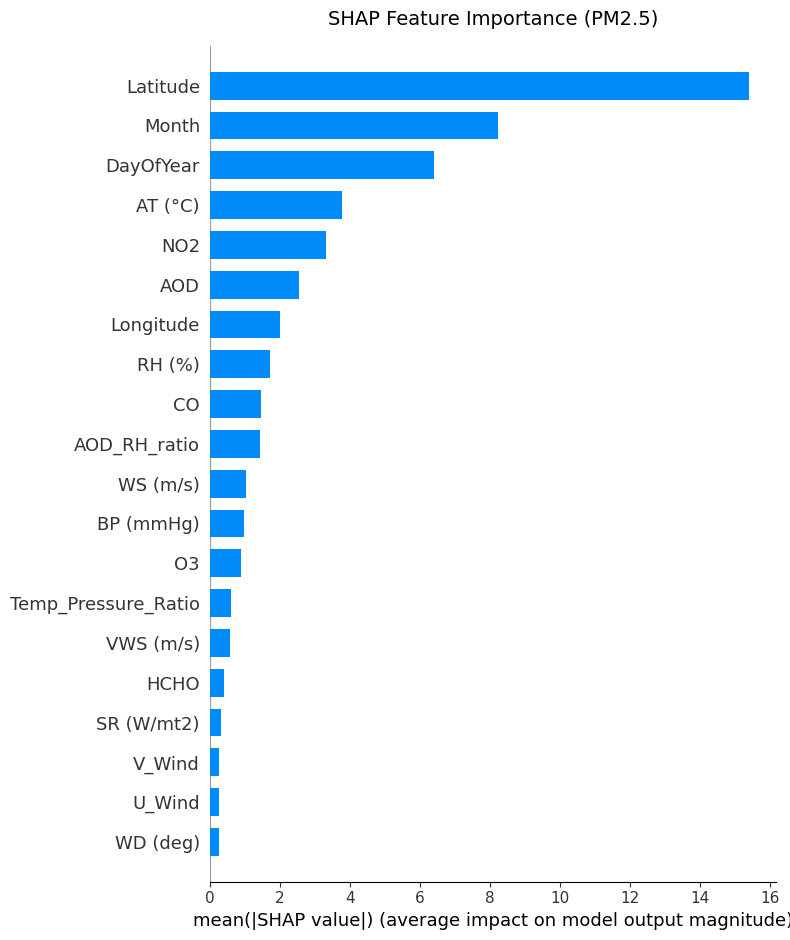

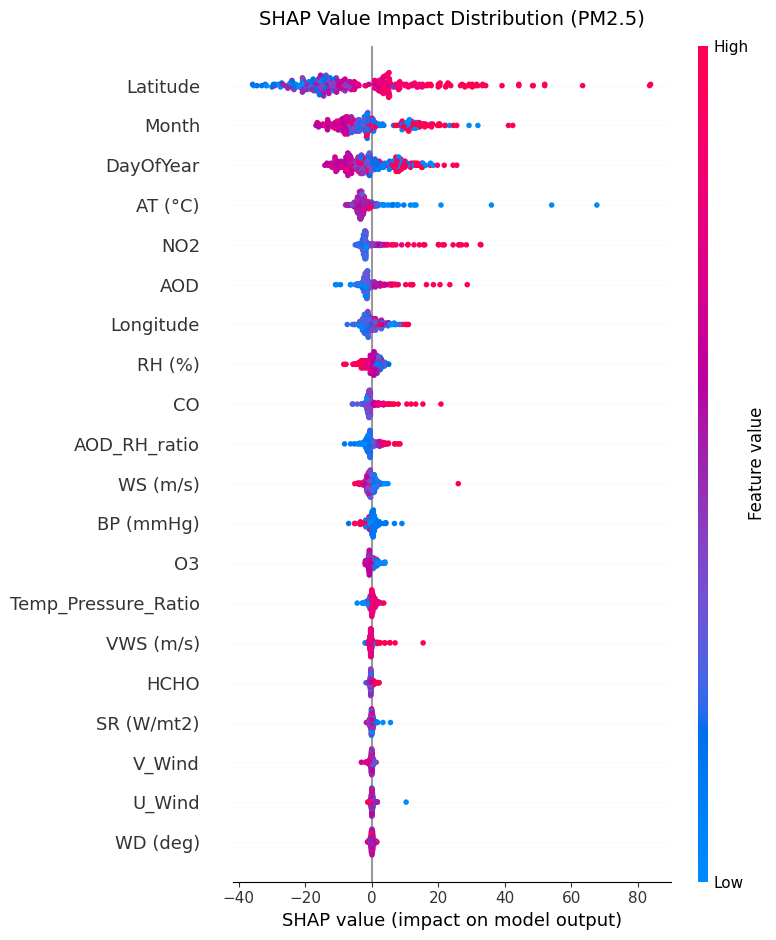

In [8]:
import shap
import matplotlib.pyplot as plt

# 1. Select target pollutant
target_pollutant = 'PM2.5'

if target_pollutant in models_dict:
    stacking_model = models_dict[target_pollutant]

    # 2. Safely extract a tree-based base estimator from the StackingRegressor
    if hasattr(stacking_model, 'named_estimators_') and 'et' in stacking_model.named_estimators_:
        base_tree_model = stacking_model.named_estimators_['et']
    elif hasattr(stacking_model, 'estimators_') and len(stacking_model.estimators_) > 0:
        base_tree_model = stacking_model.estimators_[0]
    else:
        base_tree_model = stacking_model

    # 3. Prepare clean sample test data
    X_sample = df_test_all[feature_cols].dropna().sample(min(300, len(df_test_all)), random_state=42)

    # 4. Compute TreeSHAP values
    explainer = shap.TreeExplainer(base_tree_model)
    shap_values = explainer(X_sample)

    # 5. Plot SHAP Feature Importance (Bar Chart)
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
    plt.title(f"SHAP Feature Importance ({target_pollutant})", fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()

    # 6. Plot SHAP Impact Distribution (Beeswarm Plot)
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_sample, show=False)
    plt.title(f"SHAP Value Impact Distribution ({target_pollutant})", fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()
else:
    print(f"⚠️ Pollutant '{target_pollutant}' not found in `models_dict`.")

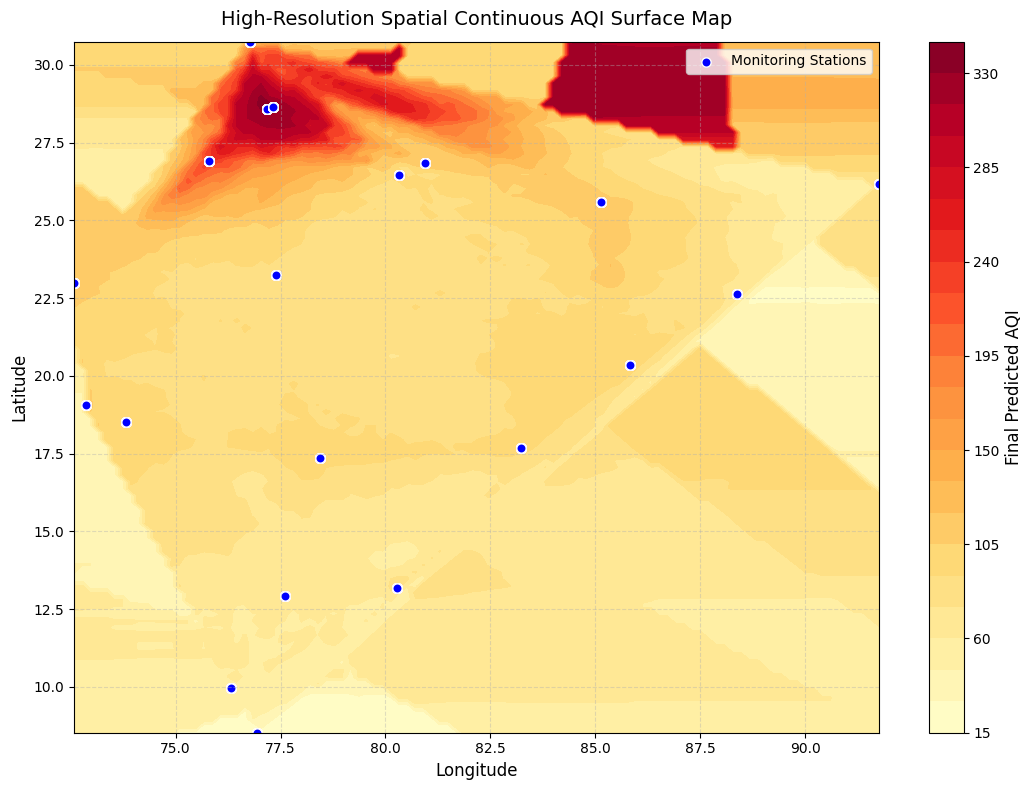

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# 1. Coordinate Grid Setup (100x100 resolution)
lat_min, lat_max = df_processed['Latitude'].min(), df_processed['Latitude'].max()
lon_min, lon_max = df_processed['Longitude'].min(), df_processed['Longitude'].max()

grid_size = 100
grid_lat, grid_lon = np.meshgrid(
    np.linspace(lat_min, lat_max, grid_size),
    np.linspace(lon_min, lon_max, grid_size)
)

grid_points = np.column_stack((grid_lat.ravel(), grid_lon.ravel()))
known_coords = df_processed[['Latitude', 'Longitude']].values

# 2. Construct Spatial Grid Feature DataFrame
grid_data = {'Latitude': grid_lat.ravel(), 'Longitude': grid_lon.ravel()}
temporal_cols = ['Month', 'DayOfWeek', 'DayOfYear', 'Hour']

for col in feature_cols:
    if col in ['Latitude', 'Longitude']:
        continue
    elif col in temporal_cols:
        # Fill temporal features with dataset median
        grid_data[col] = df_processed[col].median()
    else:
        # Spatial linear interpolation for environmental features
        vals = griddata(known_coords, df_processed[col].values, grid_points, method='linear')

        # Fallback to nearest-neighbor for border areas outside convex hull
        nan_mask = np.isnan(vals)
        if nan_mask.any():
            vals[nan_mask] = griddata(known_coords, df_processed[col].values, grid_points[nan_mask], method='nearest')

        grid_data[col] = vals

X_grid = pd.DataFrame(grid_data)[feature_cols]

# 3. Predict Pollutants and Compute Spatial Sub-Indices
grid_sub_indices = []

for pollutant in targets.keys():
    if pollutant in models_dict:
        model = models_dict[pollutant]
        grid_preds = np.maximum(0, model.predict(X_grid))

        # Calculate sub-index per point using existing function
        sub_idxs = [calculate_sub_index(val, pollutant) for val in grid_preds]
        grid_sub_indices.append(sub_idxs)

# Final Spatial AQI is maximum sub-index across all criteria pollutants
grid_aqi_array = np.max(grid_sub_indices, axis=0).reshape(grid_size, grid_size)

# 4. Render Continuous Spatial Heatmap
plt.figure(figsize=(11, 8))
contour = plt.contourf(grid_lon, grid_lat, grid_aqi_array, levels=30, cmap='YlOrRd')
cbar = plt.colorbar(contour)
cbar.set_label('Final Predicted AQI', fontsize=12)

# Overlay ground station locations
plt.scatter(
    df_processed['Longitude'],
    df_processed['Latitude'],
    c='blue',
    edgecolors='white',
    s=45,
    label='Monitoring Stations'
)

plt.title('High-Resolution Spatial Continuous AQI Surface Map', fontsize=14, pad=12)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()